# Red neurnoal para distinguir imagenes de gatos y perros. CNN propia y ResNet18.

## Paso 1: Exportar los datos de kaggle. 
Los dejamos en dos carpetas (train y test1). Los vamos a ir usando desde el disco duro que es donde están (demasiado grandes para entrar en memoria como en el caso de titanic).

#### Comando para obtener los datos y estructura del proyecto:

pip install kaggle pillow   
kaggle competitions download -c dogs-vs-cats

dogs-vs-cats/   
├── train/   (cat.0.jpg, cat.1.jpg, ..., dog.12499.jpg)     
└── test1/   (1.jpg, 2.jpg, ..., 12500.jpg)


In [ ]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

DATA = Path("dogs-vs-cats")
train_dir = DATA / "train"
test_dir = DATA / "test1"

# ---------- 1. Listar ficheros y sacar la etiqueta del nombre ----------
ficheros = sorted(train_dir.glob("*.jpg"))
df = pd.DataFrame({"path": ficheros})
df["clase"] = df["path"].apply(lambda p: "cat" if p.name.startswith("cat") else "dog")
df["label"] = (df["clase"] == "dog").astype(int)       # gato = 0, perro = 1

print("Imágenes en train:", len(df))
print(df["clase"].value_counts())
print("Imágenes en test :", len(list(test_dir.glob("*.jpg"))))

In [ ]:
# ---------- 2. ¿Qué tamaños tienen las imágenes? (muestra de 2000) ----------
muestra = df.sample(2000, random_state=0)
tamanos = [Image.open(p).size for p in muestra["path"]]     # (ancho, alto); solo lee la cabecera
tam = pd.DataFrame(tamanos, columns=["ancho", "alto"])
tam["proporcion"] = tam["ancho"] / tam["alto"]
print(tam.describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(tam["ancho"], bins=40);       axes[0].set_title("Ancho (px)")
axes[1].hist(tam["alto"], bins=40);        axes[1].set_title("Alto (px)")
axes[2].hist(tam["proporcion"], bins=40);  axes[2].set_title("Proporción ancho/alto")
plt.tight_layout(); plt.show()

In [ ]:
# ---------- 3. Ver ejemplos ----------
random.seed(1)
elegidas = df.sample(8, random_state=1)

fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, (_, fila) in zip(axes.flat, elegidas.iterrows()):
    img = Image.open(fila["path"])
    ax.imshow(img)
    ax.set_title(f"{fila['clase']}  {img.size[0]}×{img.size[1]}")
    ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# Y una comprobación opcional (tarda ~1 minuto) por si hubiese ficheros corruptos, 
# algo que ocurre en algunos datasets de imágenes y rompería el entrenamiento a mitad de una época:

corruptas = []
for p in df["path"]:
    try:
        with Image.open(p) as img:
            img.verify()
    except Exception:
        corruptas.append(p)
print("Imágenes corruptas:", len(corruptas))

## Paso 2: Paso 2: Dataset, transformaciones y DataLoader

1. Tamaños distintos. La capa Linear final necesita entradas de tamaño fijo, y hay tres formas de igualar las fotos:

- Redimensionar a la fuerza (por ejemplo a 128×128): conserva toda la imagen, pero deforma las proporciones.
- Redimensionar el lado corto y recortar el centro: conserva las proporciones, pero puede cortar los bordes. Es lo que haremos, porque en estas fotos el animal suele estar bastante centrado.
- Añadir bordes (padding): no deforma ni corta, pero mete franjas vacías que la red tiene que aprender a ignorar.

2. Qué va en train y qué en validación. Los pasos deterministas (redimensionar, recortar el centro, normalizar) deben ser idénticos en ambos. Los aleatorios (voltear, rotar, recortes al azar) van solo en train, como en MNIST.

3. Cargaremos cada imagen desde disco cuando el DataLoader la pida (lazy loading), y lo haremos en paralelo.

### Creamos los dataloaders con los workers dentro de una función en el código **datos.py** ya que sino los workers dan error!!!!!

Si trabajas con un script .py, protege el código principal para que los workers no lo ejecuten de nuevo:

- entrenar.py
from datos import crear_loaders

if __name__ == "__main__":
    train_loader, val_loader, test_loader, test_files = crear_loaders(num_workers=8)    
    # ... resto del programa

In [ ]:
import time
from datos import crear_loaders

train_loader, val_loader, test_loader, test_files = crear_loaders(num_workers=12)

it = iter(train_loader)
next(it)                          # el primer lote incluye el arranque de los workers
t0 = time.time()
for i in range(30):
    next(it)
print(f"30 lotes en {time.time() - t0:.1f} s")

Comprobar cuantos workers son los optimos (4-12):

In [ ]:
for nw in [0, 4, 8, 12]:
    tl, *_ = crear_loaders(num_workers=nw)
    it = iter(tl)
    next(it)                                   # excluye el arranque
    t0 = time.time()
    for _ in range(30):
        next(it)
    print(f"num_workers={nw:2d}: {30 * 64 / (time.time() - t0):6.0f} imágenes/s")
    del it, tl                                 # libera los workers antes de la siguiente prueba

Comprobaciones:

In [ ]:
import time
from PIL import Image

# Prueba 1: ¿cuánto tarda en leer UNA imagen del disco? (200 imágenes)
t0 = time.time()
for p in df_tr["path"].iloc[:200]:
    Image.open(p).convert("RGB")
print(f"Prueba 1 - leer 200 imágenes: {time.time() - t0:.1f} s")

# Prueba 2: lo mismo pero con las transformaciones (sin DataLoader ni workers)
t0 = time.time()
for i in range(200):
    ds_tr[i]
print(f"Prueba 2 - leer + transformar 200 imágenes: {time.time() - t0:.1f} s")

# Prueba 3: DataLoader SIN multiprocesamiento (10 lotes = 640 imágenes)
loader0 = DataLoader(ds_tr, batch_size=64, shuffle=True, num_workers=0)
t0 = time.time()
for i, (x, y) in enumerate(loader0):
    if i == 9:
        break
print(f"Prueba 3 - 10 lotes con num_workers=0: {time.time() - t0:.1f} s")

In [ ]:
# ---------- Formas, tipos y estadísticas ----------
imgs, labels = next(iter(train_loader))
print(imgs.shape, imgs.dtype)       # torch.Size([64, 3, 128, 128]) torch.float32
print(labels.shape, labels.dtype)   # torch.Size([64]) torch.float32
print("Media por canal:", imgs.mean(dim=(0, 2, 3)))
print("Std por canal:  ", imgs.std(dim=(0, 2, 3)))
print("Proporción de perros en el lote:", labels.mean().item())

# ---------- Ver imágenes (hay que des-normalizar para mostrarlas) ----------
def desnormalizar(x):
    media = torch.tensor(MEDIA).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    return (x * std + media).clamp(0, 1)

fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for ax, img, lab in zip(axes.flat, imgs, labels):
    ax.imshow(desnormalizar(img).permute(1, 2, 0))     # [3,H,W] -> [H,W,3] para matplotlib
    ax.set_title("perro" if lab == 1 else "gato")
    ax.axis("off")
plt.tight_layout(); plt.show()

# ---------- ¿Cuánto tarda en cargar? (50 lotes) ----------
t0 = time.time()
for i, (x, y) in enumerate(train_loader):
    if i == 49:
        break
print(f"50 lotes en {time.time() - t0:.1f} s")

## Paso 3: la CNN propia, desde cero

Es la misma receta que en MNIST (convolución → pooling → clasificador), con cuatro cambios por el nuevo problema:

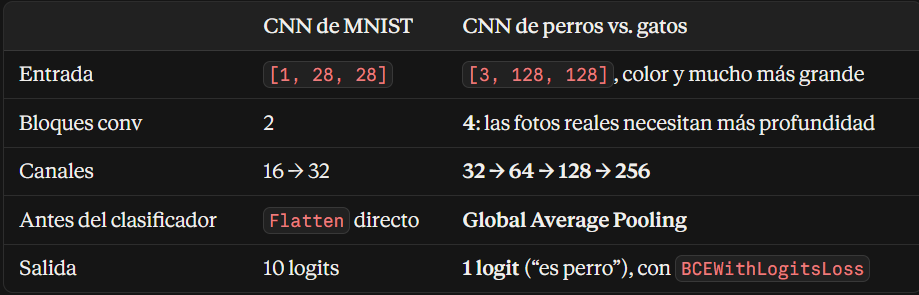  

la estructura:

Imagen [3, 128, 128]    
  ↓ Bloque 1: Conv(3→32)    + BN + ReLU + MaxPool  → [32, 64, 64]   
  ↓ Bloque 2: Conv(32→64)   + BN + ReLU + MaxPool  → [64, 32, 32]   
  ↓ Bloque 3: Conv(64→128)  + BN + ReLU + MaxPool  → [128, 16, 16]  
  ↓ Bloque 4: Conv(128→256) + BN + ReLU + MaxPool  → [256, 8, 8]    
  ↓ AdaptiveAvgPool2d(1)                           → [256, 1, 1]    
  ↓ Flatten → Dropout(0.3) → Linear(256 → 1)       → [1]    

El patrón de “menos tamaño espacial, más canales” es estándar en CNNs: al bajar de 128×128 a 8×8 se pierde dónde está cada cosa, y a cambio los canales pasan de 3 a 256 y cada uno detecta un patrón distinto (bordes → texturas → orejas, hocicos...).

In [8]:
import torch
from torch import nn

device = "cuda" if torch.cuda.is_available() else "cpu"

def bloque(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1), # padding=1 con kernel 3×3. Mantiene el tamaño espacial.
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2), # Es el MaxPool2d(2) el que lo reduce a la mitad en cada bloque: (divide la 
                         # imagen en bloques 2x2 y se queda con el pixel de mayor intensidad en cada bloque)
    )

class CNNPerrosGatos(nn.Module):
    def __init__(self, canales=(32, 64, 128, 256), dropout=0.3):
        super().__init__()
        bloques, c_in = [], 3
        for c in canales:
            bloques.append(bloque(c_in, c))
            c_in = c
        self.features = nn.Sequential(*bloques)
        self.pool = nn.AdaptiveAvgPool2d(1)            # [B, C, H, W] -> [B, C, 1, 1]
        self.classifier = nn.Sequential(
            nn.Flatten(),                              # -> [B, 256]
            nn.Dropout(dropout),
            nn.Linear(c_in, 1),                        # un solo logit
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x).squeeze(1)           # [B, 1] -> [B]

model = CNNPerrosGatos().to(device)
print("Parámetros:", sum(p.numel() for p in model.parameters()))   # 389.633

Parámetros: 389633


AdaptiveAvgPool2d(1) (Global Average Pooling). Es lo nuevo importante. Para cada canal, promedia todo su mapa de 8×8 en un solo número: [256, 8, 8] pasa a [256]. Frente a un Flatten directo (que daría 256×8×8 = 16.384 valores) aporta tres cosas:

* Muchos menos parámetros y, por tanto, menos riesgo de sobreajuste.
* Cada canal actúa como un detector de “¿aparece este patrón en algún sitio de la foto?”, sin importar dónde. Eso encaja con el problema: el perro puede estar a la izquierda, a la derecha o ser solo una cara.
* Funciona con cualquier tamaño de entrada, porque siempre colapsa a 1×1. Lo aprovecharemos con ResNet18, que usa exactamente esta técnica.

Comprobaciones antes de entrenar:

In [ ]:
# Formas capa a capa:

x = torch.randn(4, 3, 128, 128, device=device)
model.eval()
with torch.no_grad():
    for i, b in enumerate(model.features):
        x = b(x)
        print(f"Bloque {i + 1}: {tuple(x.shape)}")
    x = model.pool(x)
    print(f"Pool:     {tuple(x.shape)}")
    print(f"Salida:   {tuple(model.classifier(x).shape)}")

In [ ]:
# Pérdida inicial: con pesos aleatorios, la red no sabe nada y reparte probabilidades a ~50 %, así que la 
# pérdida debería rondar -log(0.5) ≈ 0.69, como en Titanic:

from datos import crear_loaders

train_loader, val_loader, test_loader, test_files = crear_loaders(num_workers=12)
loss_fn = nn.BCEWithLogitsLoss()

imgs, labels = next(iter(train_loader))
model.eval()
with torch.no_grad():
    loss = loss_fn(model(imgs.to(device)), labels.to(device))
print("Pérdida inicial:", loss.item())    # ~0.69 (entre 0.6 y 0.8 es normal)

In [ ]:
# Sobreajustar un solo lote. Es el test más útil para detectar errores. Si el modelo y el bucle 
# de entrenamiento están bien, una red con capacidad de sobra debe poder memorizar 64 imágenes hasta 
# llevar la pérdida casi a 0. Si no puede, hay un error (etiquetas mal alineadas, falta zero_grad, tipos incorrectos...):

modelo_test = CNNPerrosGatos(dropout=0.0).to(device)       # sin dropout para esta prueba
opt = torch.optim.Adam(modelo_test.parameters(), lr=1e-3)

x, y = imgs.to(device), labels.to(device)                  # el MISMO lote siempre
modelo_test.train()
for paso in range(60):
    loss = loss_fn(modelo_test(x), y)
    opt.zero_grad()
    loss.backward()
    opt.step()
    if paso % 10 == 0 or paso == 59:
        acc = ((modelo_test(x) > 0).float() == y).float().mean().item()
        print(f"paso {paso:2d} | pérdida {loss.item():.4f} | acc (mismo lote) {acc:.0%}")

¿Es la GPU o son los datos el cuello de botella?

Ya sabes que tu DataLoader entrega ~4.400 img/s. Mide cuántas imágenes por segundo puede procesar la GPU con este modelo, usando datos aleatorios para aislar el cálculo:

In [ ]:
import time

modelo_b = CNNPerrosGatos().to(device)
opt = torch.optim.Adam(modelo_b.parameters(), lr=1e-3)
x = torch.randn(64, 3, 128, 128, device=device)
y = torch.randint(0, 2, (64,), device=device).float()

def paso_entrenamiento():
    loss = loss_fn(modelo_b(x), y)
    opt.zero_grad(); loss.backward(); opt.step()

for _ in range(5):                       # calentamiento (primeras iteraciones más lentas)
    paso_entrenamiento()
if device == "cuda":
    torch.cuda.synchronize()
t0 = time.time()
for _ in range(50):
    paso_entrenamiento()
if device == "cuda":
    torch.cuda.synchronize()             # esperar a que la GPU termine de verdad
print(f"GPU: {50 * 64 / (time.time() - t0):.0f} imágenes/s en entrenamiento")

Tu GPU procesa 1.761 img/s y tus workers entregan hasta 4.394 img/s. Ahora el límite es la GPU y no los datos.

Un truco para acelerar: precisión mixta

Tu RTX 4060 tiene tensor cores, unidades que multiplican matrices mucho más rápido si usan 16 bits en vez de 32. La precisión mixta (torch.autocast) hace los cálculos pesados (convoluciones, Linear) en 16 bits y mantiene en 32 bits las operaciones sensibles, como la pérdida. Suele dar entre 1,3× y 2× de velocidad, aunque no te lo puedo garantizar: mídelo. Lo dejamos como interruptor (USO_AMP) para que compares.

Usamos bfloat16, que tiene el mismo rango numérico que float32, por lo que no necesita GradScaler y el código queda igual de simple que antes. Tu GPU (arquitectura Ada) lo soporta.

In [ ]:
import time
import copy
import torch
import matplotlib.pyplot as plt
from torch import nn

USO_AMP = True                                   # pon False para comparar velocidades
torch.backends.cudnn.benchmark = True            # elige los algoritmos de convolución más rápidos
                                                 # (útil porque todas las entradas tienen el mismo tamaño)
def autocast():
    return torch.autocast(device_type="cuda", dtype=torch.bfloat16,
                          enabled=USO_AMP and device == "cuda")

def entrenar_una_epoca(model, loader, loss_fn, optimizer):
    model.train()
    perdida_total = torch.zeros((), device=device)
    correctas = torch.zeros((), device=device)
    n = 0
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        with autocast():
            pred = model(x)
            loss = loss_fn(pred.float(), y)      # la pérdida siempre en float32

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        perdida_total += loss.detach() * len(y)  # ponderada: el último lote es más pequeño
        correctas += ((pred.detach() > 0).float() == y).sum()
        n += len(y)
    return perdida_total.item() / n, correctas.item() / n

def evaluar(model, loader, loss_fn):
    model.eval()
    perdida_total = torch.zeros((), device=device)
    correctas = torch.zeros((), device=device)
    n = 0
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            with autocast():
                pred = model(x)
            perdida_total += loss_fn(pred.float(), y) * len(y)
            correctas += ((pred > 0).float() == y).sum()
            n += len(y)
    return perdida_total.item() / n, correctas.item() / n

def entrenar(model, train_loader, val_loader, epocas=15, lr=1e-3, weight_decay=1e-4):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    mejor = {"val_loss": float("inf"), "epoca": 0, "estado": None}

    for epoca in range(1, epocas + 1):
        t0 = time.time()
        tl, ta = entrenar_una_epoca(model, train_loader, loss_fn, optimizer)
        vl, va = evaluar(model, val_loader, loss_fn)
        for k, v in zip(h, (tl, vl, ta, va)):
            h[k].append(v)

        if vl < mejor["val_loss"]:
            mejor = {"val_loss": vl, "epoca": epoca, "estado": copy.deepcopy(model.state_dict())} # guardamos los pesos de la época 
                                                                                                  # con menor pérdida de validación.

        print(f"Época {epoca:2d}/{epocas} | {time.time() - t0:4.1f} s | "
              f"train: {tl:.4f} ({ta:.1%}) | val: {vl:.4f} ({va:.1%})")
    return h, mejor

# ---------- Entrenar ----------
torch.manual_seed(0)
model = CNNPerrosGatos().to(device)
historial, mejor = entrenar(model, train_loader, val_loader, epocas=15)
print(f"Mejor época por pérdida de validación: {mejor['epoca']}") 

torch.save(mejor["estado"], "cnn_scratch.pt") # model queda con los pesos de la última época, no los de la mejor. 
                                              # Si quieres evaluar la mejor, usa model.load_state_dict(mejor["estado"]).

In [ ]:
def dibujar_historial(h):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

    ax1.plot(ep, h["train_loss"], marker="o", label="Train")
    ax1.plot(ep, h["val_loss"], marker="o", label="Validación")
    ax1.set_xlabel("Época"); ax1.set_ylabel("Pérdida")
    ax1.set_title("Pérdida por época"); ax1.legend(); ax1.grid(alpha=0.3)

    ax2.plot(ep, [a * 100 for a in h["train_acc"]], marker="o", label="Train")
    ax2.plot(ep, [a * 100 for a in h["val_acc"]], marker="o", label="Validación")
    ax2.axhline(50, color="gray", linestyle="--", label="Azar (50 %)")
    ax2.set_xlabel("Época"); ax2.set_ylabel("Precisión (%)")
    ax2.set_title("Precisión por época"); ax2.legend(); ax2.grid(alpha=0.3)

    plt.tight_layout(); plt.show()

#dibujar_historial(historial)

## Paso 5: data augmentation.
Tenemos sobreajuste, hay que arreglarlo. Cada vez que la red pide una imagen, le damos una versión ligeramente distinta. Con 20.000 fotos el sobreajuste es el límite principal (train sube, validación se estanca), y el augmentation ataca eso sin cambiar la arquitectura.

Hay dos diferencias con MNIST:

* Ahora sí vale el volteo horizontal. Un perro volteado sigue siendo un perro. En MNIST era mala idea, porque un 2 volteado ya no es un 2. La regla es la misma de siempre: ¿seguiría una persona viendo la misma clase?
* Las fotos son grandes y variadas, así que podemos recortar trozos al azar. Eso entrena a la red para reconocer al animal aunque salga parcial o a otra escala.

hacemos cambios en datos.py (transform_train_aug = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0), ratio=(0.75, 1.33)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, STD),
]))

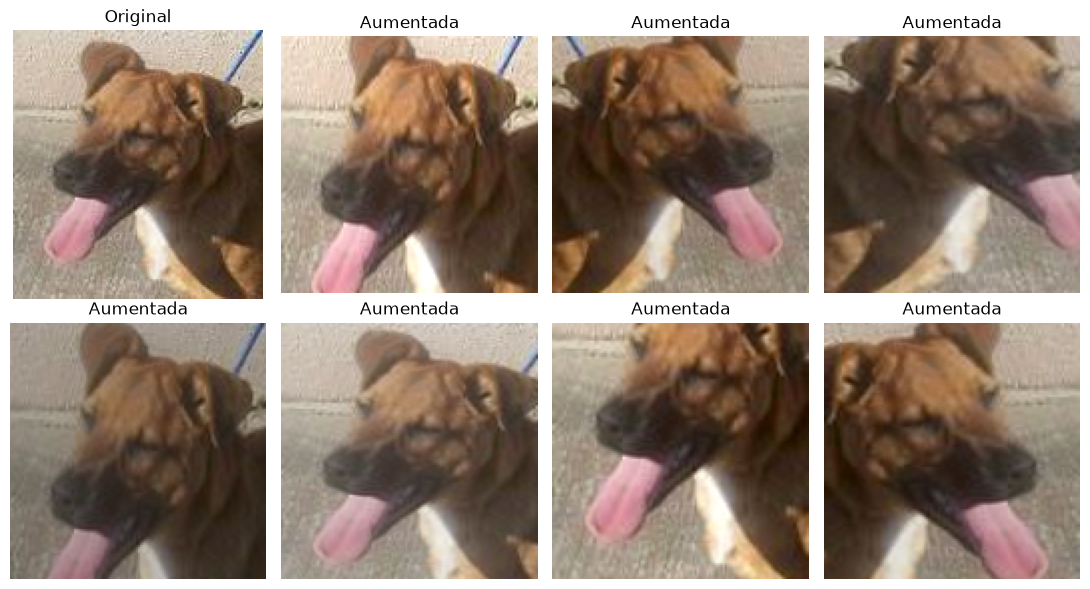

In [2]:
from PIL import Image
from datos import transform_train_aug
from datos import crear_loaders
import matplotlib.pyplot as plt
import torch

train_loader, val_loader, test_loader, test_files = crear_loaders(num_workers=12)

MEDIA = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

def desnormalizar(x):
    media = torch.tensor(MEDIA).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    return (x * std + media).clamp(0, 1)


ruta = train_loader.dataset.paths[0]
original = Image.open(ruta).convert("RGB")

fig, axes = plt.subplots(2, 4, figsize=(11, 6))
axes[0, 0].imshow(original); axes[0, 0].set_title("Original")
for ax in axes.flat[1:]:
    ax.imshow(desnormalizar(transform_train_aug(original)).permute(1, 2, 0))
    ax.set_title("Aumentada")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.show()

In [11]:
# entrena el mismo modelo con augmentation

"""historial_base = historial"""          # el entrenamiento sin augmentation del paso 4

train_loader, val_loader, test_loader, test_files = crear_loaders(num_workers=12, augmentation=True)

torch.manual_seed(0)
model = CNNPerrosGatos().to(device)
historial_aug, mejor_aug = entrenar(model, train_loader, val_loader, epocas=30)
print(f"Mejor época: {mejor_aug['epoca']}")
torch.save(mejor_aug["estado"], "cnn_aug.pt")

dibujar_historial(historial_aug)

Época  1/30 | 103.9 s | train: 0.6007 (67.9%) | val: 0.6398 (65.9%)
Época  2/30 | 13.2 s | train: 0.5362 (73.4%) | val: 0.4869 (76.8%)
Época  3/30 | 11.0 s | train: 0.4932 (76.7%) | val: 0.6039 (68.6%)
Época  4/30 | 10.6 s | train: 0.4408 (79.8%) | val: 0.5217 (75.8%)
Época  5/30 | 10.6 s | train: 0.3963 (82.2%) | val: 0.4240 (79.3%)
Época  6/30 | 10.6 s | train: 0.3640 (83.8%) | val: 0.6575 (72.0%)
Época  7/30 | 11.2 s | train: 0.3419 (85.1%) | val: 0.3999 (81.1%)
Época  8/30 | 11.0 s | train: 0.3167 (86.5%) | val: 0.6825 (72.1%)
Época  9/30 | 11.2 s | train: 0.2967 (87.2%) | val: 0.6772 (71.7%)
Época 10/30 | 11.2 s | train: 0.2876 (87.8%) | val: 0.3018 (86.3%)
Época 11/30 | 11.0 s | train: 0.2716 (88.8%) | val: 0.2498 (89.1%)
Época 12/30 | 13.2 s | train: 0.2575 (89.2%) | val: 0.2222 (91.3%)
Época 13/30 | 11.8 s | train: 0.2459 (89.9%) | val: 0.6050 (79.1%)
Época 14/30 | 11.5 s | train: 0.2360 (90.4%) | val: 0.2734 (89.7%)
Época 15/30 | 11.9 s | train: 0.2258 (90.8%) | val: 0.1943 (9

NameError: name 'dibujar_historial' is not defined

In [3]:
def evaluar_tta(model, loader):
    model.eval(); correctas, n = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logit = (model(x) + model(torch.flip(x, dims=[3]))) / 2   # flip horizontal
            correctas += ((logit > 0).float() == y).sum().item(); n += len(y)
    return correctas / n

model.load_state_dict(mejor_aug["estado"])
print("Val acc con TTA:", evaluar_tta(model, val_loader))

NameError: name 'model' is not defined

## Paso 6: transfer learning con ResNet18

La idea

Hasta ahora la red empezaba sin saber nada: tenía que aprender qué es un borde, una textura o una oreja solo con 20.000 fotos. Con transfer learning partimos de una red que ya lo sabe.

ResNet18 fue entrenada con ImageNet, 1,2 millones de fotos en 1.000 categorías. Entre ellas hay más de 100 razas de perro y varias clases de gato, así que lo que aprendió es casi directamente lo que necesitamos. Solo hay que quitarle la última capa (que decide entre 1.000 clases) y poner una nueva que decida entre 2.

Lo haremos en dos fases:

- Paso 6 (ahora): extracción de características. Congelamos toda la red preentrenada y entrenamos solo la capa nueva. Es muy rápido y ya da un gran resultado.
- Paso 7: fine-tuning. Descongelamos parte de la red y la ajustamos con un learning rate pequeño.

### Qué es una ResNet

La novedad de ResNet son las conexiones residuales (skip connections). Cada bloque calcula salida = F(x) + x: además de pasar x por dos convoluciones, **suma la entrada original** al resultado.

x ──→ Conv → BN → ReLU → Conv → BN ──→ (+) → ReLU → salida      
 └───────────────────────────────┘     
                (atajo: se suma x)        

Así el bloque solo tiene que aprender la diferencia respecto a la entrada, y los gradientes pueden fluir directamente por el atajo hacia las capas iniciales. Eso permite entrenar redes muy profundas sin que el gradiente se desvanezca. Nuestra CNN tenía 4 capas convolucionales; ResNet18 tiene 17 más la final (de ahí el “18”).

La estructura de ResNet18:

Imagen [3, H, W]    
  ↓ Conv 7×7 (stride 2) + BN + ReLU + MaxPool   
  ↓ Etapa 1: 2 bloques residuales, 64 canales   (layer1)    
  ↓ Etapa 2: 2 bloques residuales, 128 canales  (layer2)    
  ↓ Etapa 3: 2 bloques residuales, 256 canales  (layer3)    
  ↓ Etapa 4: 2 bloques residuales, 512 canales  (layer4)    
  ↓ Global Average Pooling  → [512]     
  ↓ Linear(512 → 1000)   ← esta es la que sustituimos por Linear(512 → 1)   

Termina con el mismo Global Average Pooling que usamos en nuestra CNN, así que acepta imágenes de cualquier tamaño.

In [4]:
import torch
from torch import nn
from torchvision import models

class ResNetPerrosGatos(nn.Module):
    def __init__(self, congelar=True, dropout=0.2):
        super().__init__()
        self.backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        self.backbone.fc = nn.Identity()                 # quitamos la capa de 1000 clases -> sale [B, 512]
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(512, 1))   # capa nueva
        self.congelar_backbone(congelar)

    def congelar_backbone(self, congelar=True):
        self.congelado = congelar
        for p in self.backbone.parameters():
            p.requires_grad = not congelar

    def train(self, mode=True):
        super().train(mode)
        if self.congelado:
            self.backbone.eval()      # mantiene las BatchNorm del backbone en modo evaluación
        return self

    def forward(self, x):
        return self.head(self.backbone(x)).squeeze(1)    # [B, 512] -> [B, 1] -> [B]

device = "cuda" if torch.cuda.is_available() else "cpu"
model = ResNetPerrosGatos(congelar=True).to(device)

total = sum(p.numel() for p in model.parameters())
entrenables = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parámetros totales: {total:,} | entrenables: {entrenables:,}")
# 11,177,025 totales | 513 entrenables

Parámetros totales: 11,177,025 | entrenables: 513


* weights=IMAGENET1K_V1: carga los pesos preentrenados. Sin este argumento, la red se inicializaría al azar.
* backbone.fc = nn.Identity(): Identity devuelve su entrada sin cambios. Es la forma más limpia de quitar la última capa: ahora el backbone devuelve el vector de 512 características de cada imagen, y nuestra head lo clasifica.
* requires_grad = False: le dice a PyTorch que no calcule gradientes para esos pesos. Como además la entrada no requiere gradiente, PyTorch no construye el grafo de retropropagación del backbone, y esa parte solo hace el forward. Por eso entrenar es más rápido y gasta menos memoria.
* El override de train(): es el detalle más importante y fácil de olvidar. Congelar los pesos con requires_grad=False no congela las capas BatchNorm, porque sus medias y varianzas acumuladas no son parámetros entrenables, sino estadísticas que se actualizan en cada forward en modo train(). Si las dejaras actualizarse, los datos de perros y gatos irían alterando poco a poco el backbone «congelado». Con este train(), el backbone queda siempre en modo eval(), tanto los pesos como las estadísticas, y solo cambia head (que tiene el dropout).
* La misma normalización de ImageNet. Usamos MEDIA y STD de ImageNet desde el paso 2 precisamente por esto: una red preentrenada espera las entradas normalizadas como se hizo en su entrenamiento. Si las normalizaras distinto, las características que produce no tendrían sentido.